# Fase 4: Visualización y comunicación de resultados

## Proyecto: Análisis de startups de Y Combinator

## Introducción

Esta cuarta fase del proyecto tiene como propósito comunicar y analizar los resultados obtenidos a partir del procesamiento y estructuración de los datos desarrollados en las fases anteriores. Para ello, se utilizará el dataset procesado y validado durante la Fase 3, evitando repetir las operaciones de limpieza y transformación previamente implementadas.

Mediante herramientas de visualización de datos, se buscará identificar patrones, distribuciones y características relevantes de las startups pertenecientes al dataset de Y Combinator, relacionando los resultados obtenidos con la problemática y los objetivos definidos inicialmente en la Fase 1.

## Objetivo de la Fase 4

Desarrollar visualizaciones e interpretaciones analíticas que permitan comunicar de manera clara y comprensible los resultados obtenidos a partir del dataset procesado, utilizando los artefactos generados en la Fase 3 y manteniendo la reproducibilidad del proyecto.

## Alcance

Esta fase contempla la integración de los datos procesados, la validación de su estructura para el análisis visual, la elaboración de visualizaciones, la interpretación de resultados, la identificación de limitaciones y la formulación de conclusiones.

El análisis se realizará sobre los datos resultantes de la Fase 3, manteniendo la coherencia metodológica y técnica con las etapas previas del proyecto.

In [27]:
# Librerías para análisis y visualización
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [28]:
def localizar_raiz():

    carpeta_actual = Path.cwd()

    if carpeta_actual.name in {
        "F1",
        "F2",
        "F3",
        "F4"
    }:
        return carpeta_actual.parent

    return carpeta_actual


RAIZ = localizar_raiz()

print("Raíz del proyecto:")
print(RAIZ)

Raíz del proyecto:
C:\Users\Casti\U-Andres-Bello\U-Andres-Bello


In [29]:
RUTA_DATASET = "../data/y-combinator-companies.csv"

df_original = pd.read_csv(
    RUTA_DATASET
)

df_original.head()

,company_id,name,yc_slug,yc_url,batch,batch_season,batch_year,batch_code,years_since_batch,status,...,website,domain,domain_tld,website_status,website_live,website_final_domain,website_redirects_offsite,checked_at,batch_size,batch_active_rate
0,32165,Rote,rote,https://www.ycombinator.com/companies/rote,Winter 2027,Winter,2027.0,W27,-1.0,Active,...,https://tryrote.com/,tryrote.com,tryrote.com,200.0,True,tryrote.com,False,2026-08-27,1,1.0
1,35290,Antropi Robotics,antropi-robotics,https://www.ycombinator.com/companies/antropi-...,Fall 2026,Fall,2026.0,F26,0.0,Active,...,https://www.antropi.world/,antropi.world,antropi.world,200.0,True,antropi.world,False,2026-08-27,23,1.0
2,35058,Capveon,capveon,https://www.ycombinator.com/companies/capveon,Fall 2026,Fall,2026.0,F26,0.0,Active,...,https://capveon.ai,capveon.ai,capveon.ai,200.0,True,capveon.ai,False,2026-08-27,23,1.0
3,31461,Collar,collar,https://www.ycombinator.com/companies/collar,Fall 2026,Fall,2026.0,F26,0.0,Active,...,https://usecollarai.com,usecollarai.com,usecollarai.com,200.0,True,usecollarai.com,False,2026-08-27,23,1.0
4,36084,Covera,covera,https://www.ycombinator.com/companies/covera,Fall 2026,Fall,2026.0,F26,0.0,Active,...,https://www.covera-agents.com/,covera-agents.com,covera-agents.com,200.0,True,covera-agents.com,False,2026-08-27,23,1.0


In [30]:
variables_analisis = [

    "name",
    "is_operating",
    "is_hiring",
    "nonprofit",
    "status",
    "is_ai",
    "team_size",
    "industry",
    "hq_country",
    "years_since_batch"

]

df = (
    df_original[
        variables_analisis
    ]
    .copy()
)

df.head()

,name,is_operating,is_hiring,nonprofit,status,is_ai,team_size,industry,hq_country,years_since_batch
0,Rote,True,False,False,Active,False,0.0,B2B,USA,-1.0
1,Antropi Robotics,True,False,False,Active,False,0.0,Industrials,India,0.0
2,Capveon,True,False,False,Active,False,2.0,Government,USA,0.0
3,Collar,True,False,False,Active,True,2.0,B2B,Singapore,0.0
4,Covera,True,True,False,Active,False,2.0,Fintech,USA,0.0


In [31]:
DIR_PROCESADO = RAIZ / "data" / "processed"

RUTA_PROCESADO = (
    DIR_PROCESADO /
    "startups_procesadas.csv"
)

print(RUTA_PROCESADO.exists())

True


In [32]:
df = pd.read_csv(
    RUTA_PROCESADO
)

print(df.shape)

df.head()

(6193, 10)


,name,is_operating,is_hiring,nonprofit,status,is_ai,team_size,industry,hq_country,years_since_batch
0,Rote,True,False,False,Active,False,0.0,B2B,USA,0.0
1,Antropi Robotics,True,False,False,Active,False,0.0,Industrials,India,0.0
2,Capveon,True,False,False,Active,False,2.0,Government,USA,0.0
3,Collar,True,False,False,Active,True,2.0,B2B,Singapore,0.0
4,Covera,True,True,False,Active,False,2.0,Fintech,USA,0.0


In [33]:
print(RUTA_PROCESADO.exists())

True


In [35]:
print("\nValores nulos:")
print(df.isna().sum())

print("\nTipos de datos:")
print(df.dtypes)


Valores nulos:
name                 0
is_operating         0
is_hiring            0
nonprofit            0
status               0
is_ai                0
team_size            0
industry             0
hq_country           0
years_since_batch    0
dtype: int64

Tipos de datos:
name                  object
is_operating            bool
is_hiring               bool
nonprofit               bool
status                object
is_ai                   bool
team_size            float64
industry              object
hq_country            object
years_since_batch    float64
dtype: object


# Pregunta 1

¿Existe una diferencia en la permanencia operativa entre startups relacionadas con inteligencia artificial y startups tradicionales?


In [37]:
permanencia_ia = (
    df
    .groupby("is_ai")["is_operating"]
    .mean()
    .reset_index()
)

permanencia_ia

,is_ai,is_operating
0,False,0.652798
1,True,0.847763


In [38]:
permanencia_ia["grupo"] = (
    permanencia_ia["is_ai"]
    .map({
        True: "IA",
        False: "Tradicional"
    })
)

permanencia_ia

,is_ai,is_operating,grupo
0,False,0.652798,Tradicional
1,True,0.847763,IA


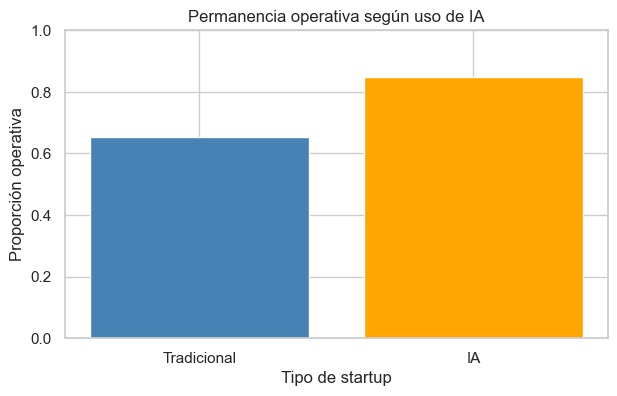

In [39]:
plt.figure(figsize=(7,4))

plt.bar(
    permanencia_ia["grupo"],
    permanencia_ia["is_operating"],
    color=["steelblue", "orange"]
)

plt.ylabel(
    "Proporción operativa"
)

plt.xlabel(
    "Tipo de startup"
)

plt.title(
    "Permanencia operativa según uso de IA"
)

plt.ylim(0, 1)

plt.show()

In [40]:
ia = permanencia_ia.loc[
    permanencia_ia["grupo"] == "IA",
    "is_operating"
].iloc[0]

tradicional = permanencia_ia.loc[
    permanencia_ia["grupo"] == "Tradicional",
    "is_operating"
].iloc[0]

print(
    f"IA: {ia:.2%}"
)

print(
    f"Tradicional: {tradicional:.2%}"
)


IA: 84.78%
Tradicional: 65.28%


# Pregunta 2
¿Cómo se relaciona la antigüedad de las startups con su permanencia operativa?

In [41]:
df["tramo_antiguedad"] = pd.cut(

    df["years_since_batch"],

    bins=[-1, 2, 5, 10, 20],

    labels=[
        "0-2 años",
        "3-5 años",
        "6-10 años",
        "11+ años"
    ]

)

In [42]:
antiguedad = (

    df
    .groupby("tramo_antiguedad")
    ["is_operating"]
    .mean()
    .reset_index()

)

antiguedad

C:\Users\Casti\AppData\Local\Temp\ipykernel_25604\3297545561.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("tramo_antiguedad")


,tramo_antiguedad,is_operating
0,0-2 años,0.961394
1,3-5 años,0.757151
2,6-10 años,0.552258
3,11+ años,0.284934


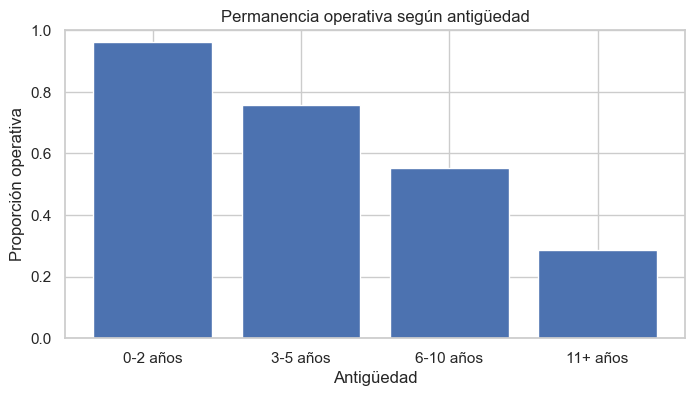

In [43]:
plt.figure(figsize=(8,4))

plt.bar(

    antiguedad["tramo_antiguedad"],
    antiguedad["is_operating"]

)

plt.ylim(0,1)

plt.xlabel(
    "Antigüedad"
)

plt.ylabel(
    "Proporción operativa"
)

plt.title(
    "Permanencia operativa según antigüedad"
)

plt.show()